# Bibliotecas

In [ ]:
# !pip install statsforecast
# !pip install pmdarima

In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from pmdarima.arima import ndiffs, auto_arima
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Dataset

In [ ]:
data_dir = '/content/drive/MyDrive/Datasets/NASA Acoustics and Vibration Database/2nd_test/2nd_test'
df_rolamento = pd.DataFrame()

for filename in os.listdir(data_dir):
    dataset = pd.read_csv(os.path.join(data_dir, filename), sep='\t')
    dataset_mean_abs = np.array(dataset.abs().mean())
    dataset_mean_abs = pd.DataFrame(dataset_mean_abs.reshape(1,4))
    dataset_mean_abs.index = [filename]
    df_rolamento = df_rolamento.append(dataset_mean_abs)

df_rolamento.columns = ['bearing_1','bearing_2','bearing_3','bearing_4']

## Ajuste do dataset

In [ ]:
df_rolamento.index = pd.to_datetime(df_rolamento.index,
                                    format='%Y.%m.%d.%H.%M.%S').sort_values()
                                    
df_rolamento.drop(columns=(['bearing_2','bearing_3','bearing_4']), inplace=True)

In [ ]:
df_rolamento.tail()

,bearing_1
2004-02-19 05:42:39,0.001857
2004-02-19 05:52:39,0.351952
2004-02-19 06:02:39,0.294231
2004-02-19 06:12:39,0.001168
2004-02-19 06:22:39,0.255120


## Análise gráfica

Text(0.5, 0, '')

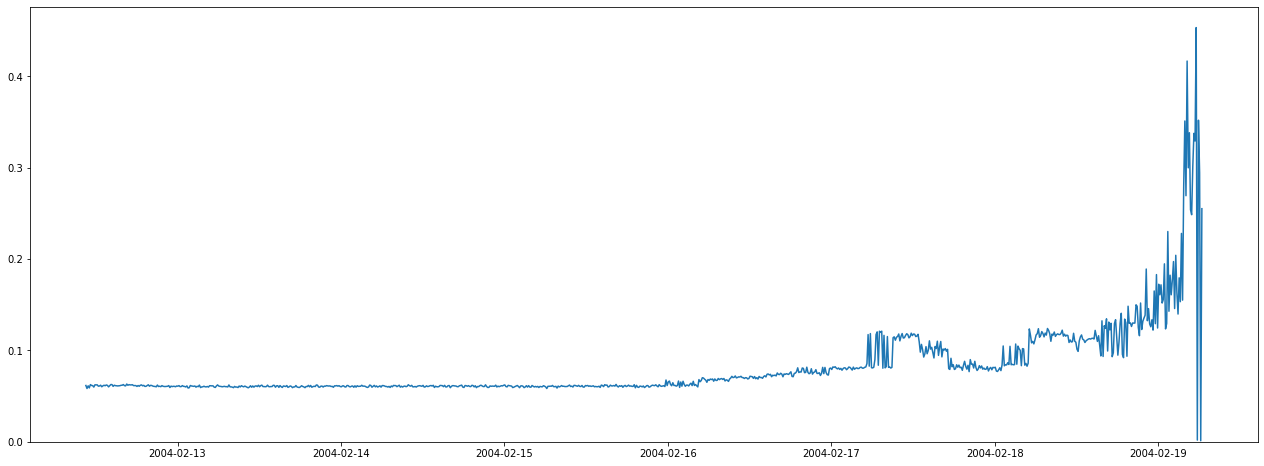

In [ ]:
ax = sns.lineplot(data=df_rolamento,
                  x=df_rolamento.index,
                  y='bearing_1')

ax.figure.set_size_inches(22,8)
ax.set_ylim(0)
ax.set_ylabel(ylabel=None)
ax.set_xlabel(xlabel=None)

# Dataset pré-falha

Text(0.5, 0, '')

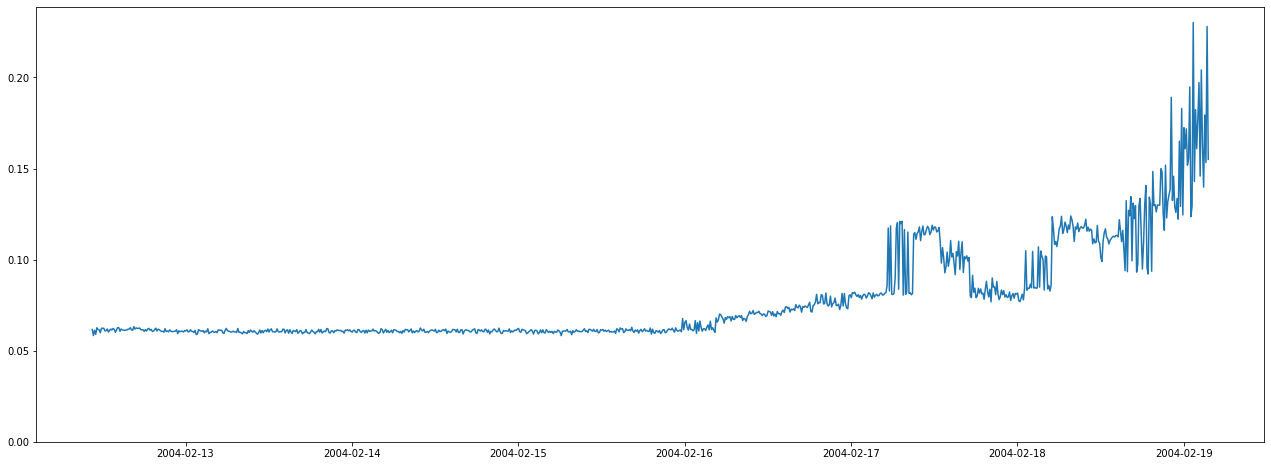

In [ ]:
df_pre_falha = df_rolamento.loc[:'2004-02-19 03:32:39'].copy()

ax = sns.lineplot(data=df_pre_falha,
                  x=df_pre_falha.index,
                  y='bearing_1')

ax.figure.set_size_inches(22,8)
ax.set_ylim(0)
ax.set_ylabel(ylabel=None)
ax.set_xlabel(xlabel=None)

# Teste de estacionariedade

## Teste de Dickey-Fuller

In [ ]:
stat_t = adfuller(df_rolamento.dropna())[0]
p_valor = adfuller(df_rolamento.dropna())[1]

valor_critico_1 = adfuller(df_rolamento.dropna())[4].get('1%')
valor_critico_5 = adfuller(df_rolamento.dropna())[4].get('5%')
valor_critico_10 = adfuller(df_rolamento.dropna())[4].get('10%')

significancia= 0.05
# Se a significância for 1% ou 10% é necessário
# alterar a condicional no if

if valor_critico_5 <= stat_t and significancia <= p_valor:
    print('Hipótese nula aceita'
          '\nSérie temporal não estacionária')
else:
    print('Hipótese nula rejeitada'
          '\nSérie temporal estacionária')

Hipótese nula aceita
Série temporal não estacionária


## Autocorrelação

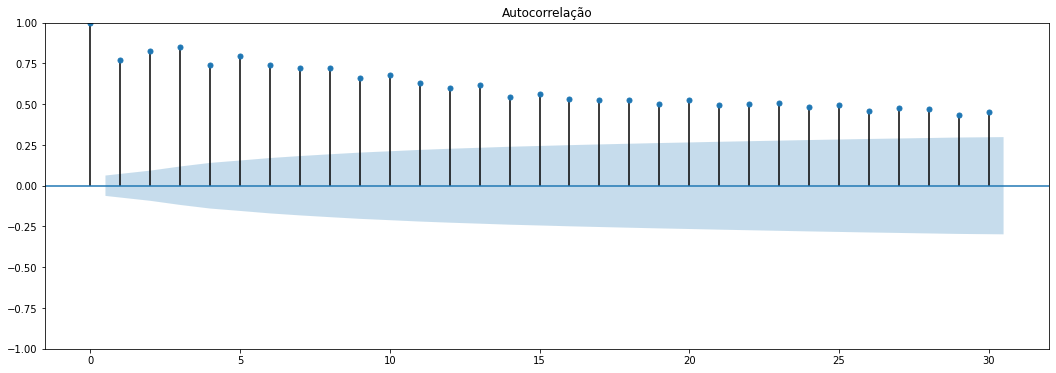

In [ ]:
autocorr = plot_acf(df_rolamento, title='Autocorrelação')
autocorr.set_figheight(6)
autocorr.set_figwidth(18)
plt.show()

## Autocorrelação parcial

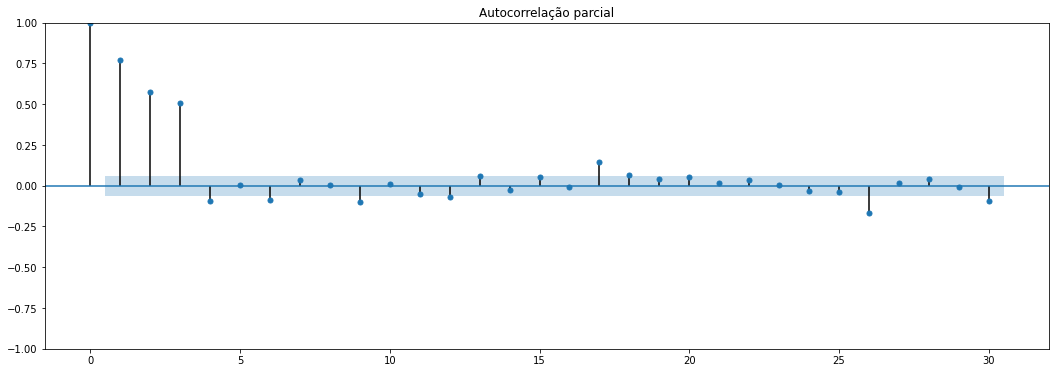

In [ ]:
autocorr_parc = plot_pacf(df_rolamento,
                          title='Autocorrelação parcial',
                          method='ywm')
autocorr_parc.set_figheight(6)
autocorr_parc.set_figwidth(18)
plt.show()

## Diferenciação

In [ ]:
ndiffs(df_rolamento, test='adf')

1

# ARIMA

## Parâmetros p, d, q

In [ ]:
auto_arima = auto_arima(df_rolamento)

auto_arima

ARIMA(order=(3, 1, 2), scoring_args={}, suppress_warnings=True,
      with_intercept=False)

In [ ]:
modelo = ARIMA(endog=df_rolamento,
               order=(3, 1, 2),
               freq='10min')

results = modelo.fit()

# print(results.summary())

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.8/dist-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## Análise dos resíduos

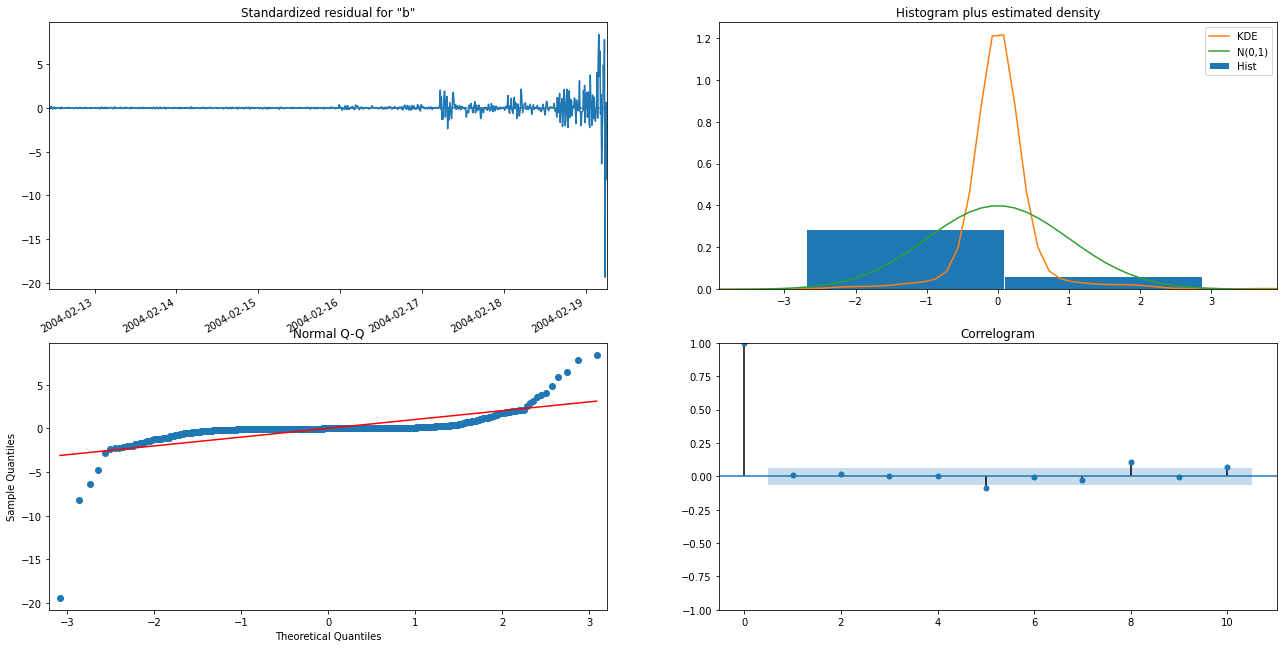

In [ ]:
results.plot_diagnostics(figsize=(22,12));

# Previsão de valores



## Treino e teste

In [ ]:
train = df_rolamento.loc[df_rolamento.index < '2004-02-18']

test = df_rolamento.loc[df_rolamento.index >= '2004-02-18']

## Interpolação

#### Modelo de previsão

In [ ]:
pred = results.get_prediction(start=test.index[0],
                              dynamic=False)

### Intervalo de confiança

In [ ]:
pred_ic = pred.conf_int()

### Análise gráfica

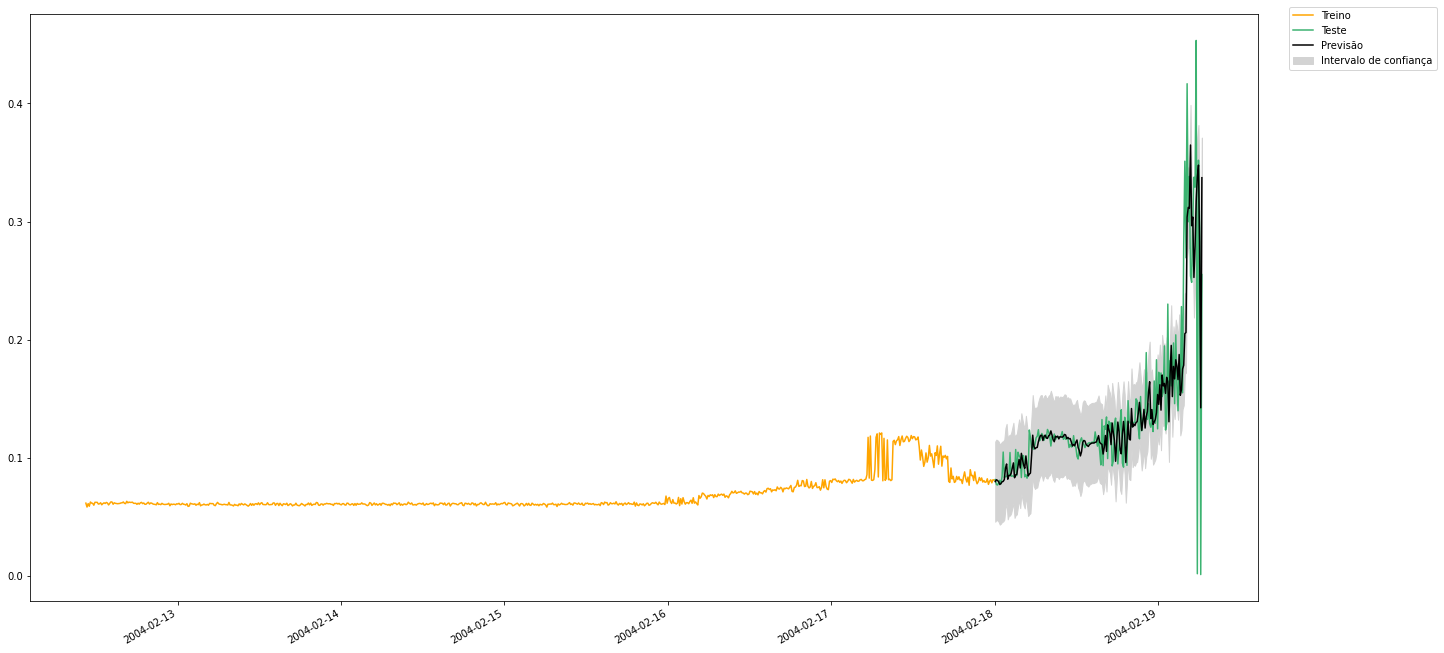

In [ ]:
ax = train.plot(color='orange')

test.plot(ax=ax, color='mediumseagreen')

pred.predicted_mean.plot(ax=ax, color='k')

ax.fill_between(pred_ic.index,
                pred_ic.iloc[:, 0],
                pred_ic.iloc[:, 1],
                color='lightgrey')

ax.figure.set_size_inches(22,12)
ax.set_xlabel(None)
ax.legend(labels=['Treino',
                  'Teste',
                  'Previsão',
                  'Intervalo de confiança'],
                   bbox_to_anchor=(1.15, 1.02))

plt.show()

### Acurácia do modelo

#### Erro quadrático médio

In [ ]:
mse = mean_squared_error(test,
                         pred.predicted_mean)

mse

0.001553207329082689

#### Coeficiente de determinação (r²)

In [ ]:
r_squared = r2_score(test,
                     pred.predicted_mean)

r_squared

0.6229687664893202

#### Erro médio absoluto

In [ ]:
mae = mean_absolute_error(test,
                          pred.predicted_mean)

mae

0.01901298216581717

## Extrapolação

In [ ]:
pred_uc = results.get_forecast(steps=6) # 6*10 min = 60 minutos à frente

### Intervalo de confiança

In [ ]:
pred_ic = pred_uc.conf_int()

### Análise gráfica

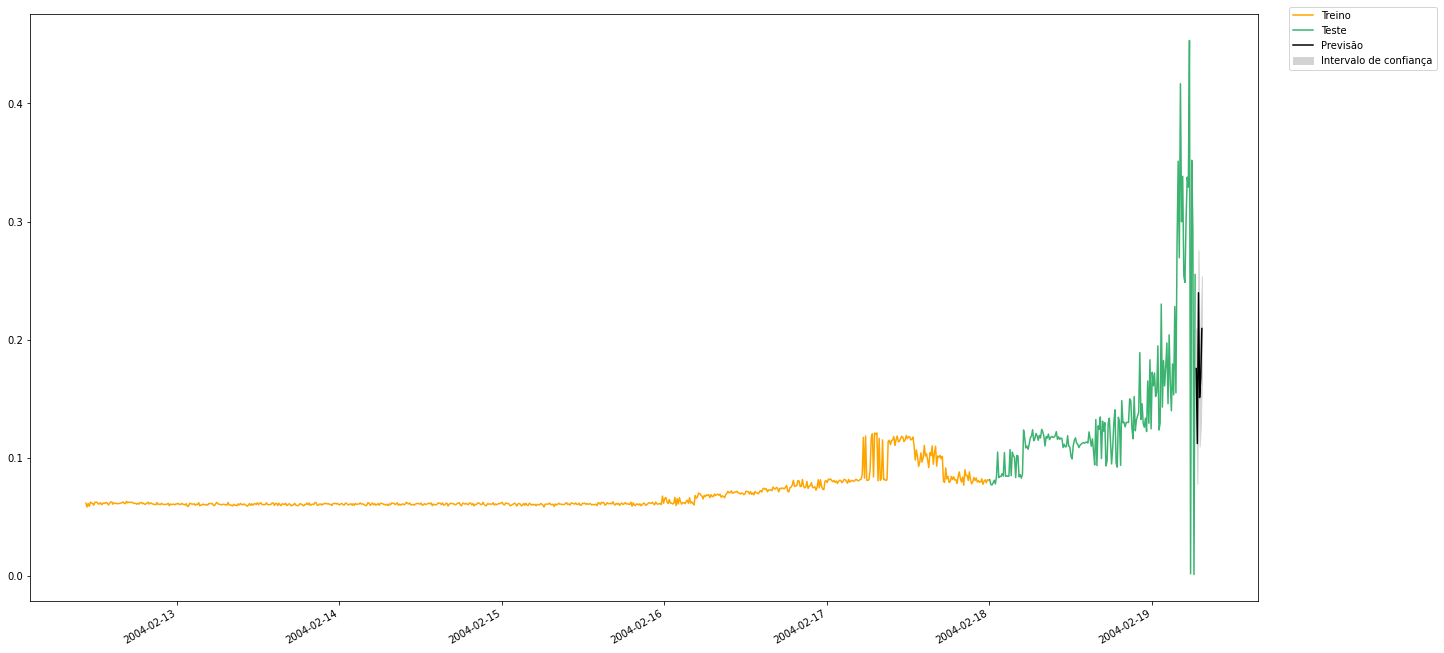

In [ ]:
fig, ax = plt.subplots(figsize=(22, 12))

train.plot(ax=ax, color='orange')
test.plot(ax=ax, color='mediumseagreen')

pred_uc.predicted_mean.plot(ax=ax, color='k')

ax.fill_between(pred_ic.index,
                pred_ic.iloc[:, 0],
                pred_ic.iloc[:, 1],
                color='lightgrey')

ax.legend(labels=['Treino', 'Teste', 'Previsão', 'Intervalo de confiança'],
          bbox_to_anchor=(1.15, 1.02))

# Cross validation

In [ ]:
# from sklearn.model_selection import cross_val_score
# from sklearn.model_selection import train_test_split
# from sklearn.model_selection import TimeSeriesSplit

In [ ]:
# ts_cv = TimeSeriesSplit(n_splits=5)

# X = df_rolamento.drop(labels=['bearing_1'], axis=1)

# y = df_rolamento['bearing_1']

In [ ]:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)